# Exercise 32 – Regression of a Lennard-Jones potential

**Week 6 · Regression**

Twelve samples of $V(r) = 4\varepsilon[(\sigma/r)^{12} - (\sigma/r)^6]$
($\varepsilon = 5$). The steep repulsive wall is hard for ordinary
polynomials. Choosing basis functions that match the physics – inverse
powers $r^{-n}$ – makes the problem easy: the exact potential is a
combination of $r^{-12}$ and $r^{-6}$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy.plotting import setup_axes
from comphy.regression import KernelRidge, PolynomialRegression, gaussian_kernel, polynomial_kernel

sigma = 2 ** (-1 / 6)
V = lambda r: 20 * ((sigma / r) ** 12 - (sigma / r) ** 6)
r_data = np.array([0.88, 0.91, 0.94, 0.97, 1.11, 1.30, 1.39, 1.49, 1.61, 1.74, 1.88, 1.97])
rs = np.linspace(0.85, 2, 400)


def compare(models, title):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(rs, V(rs), color="black", label="target")
    ax.scatter(r_data, V(r_data), color="black", zorder=3)
    for i, model in enumerate(models):
        model.fit(r_data, V(r_data))
        ax.plot(rs, model.predict(rs), color=f"C{i + 1}", label=model.label())
    setup_axes(ax, xlim=(0.85, 2), ylim=(-6, 5), xlabel="r", ylabel="V(r)", title=title)
    ax.legend(fontsize=8)
    plt.show()

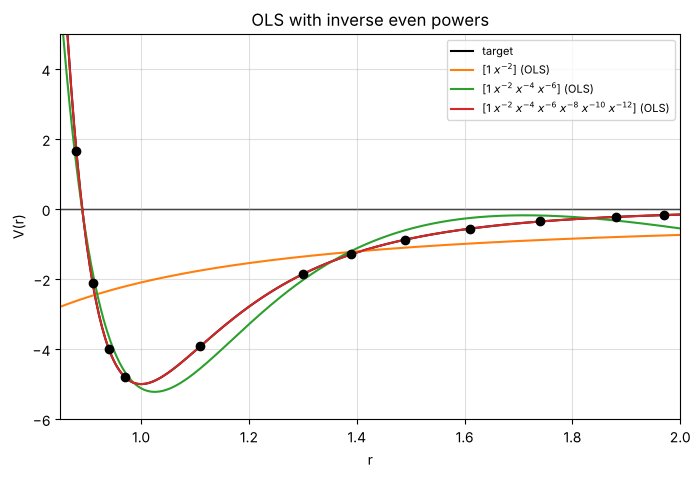

In [2]:
compare([PolynomialRegression([0, -2]), PolynomialRegression([0, -2, -4, -6]),
         PolynomialRegression(range(0, -13, -2))],
        "OLS with inverse even powers")

With $\{1, r^{-2}, \dots, r^{-12}\}$ the target lies inside the model space
and the fit is exact.

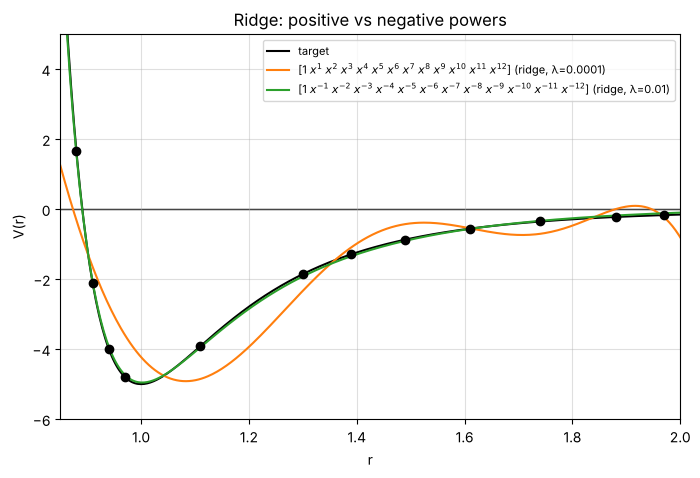

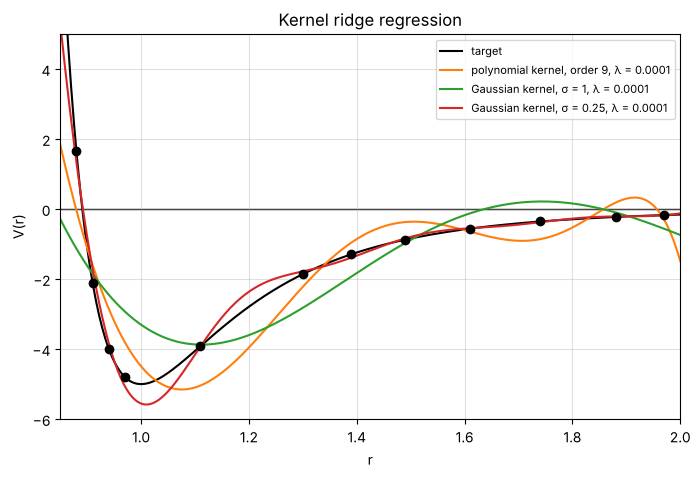

In [3]:
compare([PolynomialRegression(range(13), lam=1e-4), PolynomialRegression(range(0, -13, -1), lam=0.01)],
        "Ridge: positive vs negative powers")

compare([KernelRidge(polynomial_kernel(9), 1e-4), KernelRidge(gaussian_kernel(1.0), 1e-4),
         KernelRidge(gaussian_kernel(0.25), 1e-4)],
        "Kernel ridge regression")

Positive powers and generic kernels can fit the data points, but they wiggle
between them, especially across the gap between 0.97 and 1.11 where the
potential has its minimum. Building physical knowledge into the basis beats
more flexibility.